# Projekt: Predykcja Rzeczywistego Zużycia Paliwa Pojazdów Osobowych

---

## 1. Źródło danych
Zbiór danych pochodzi z oficjalnego raportu **Europejskiej Agencji Środowiska (EEA - European Environment Agency)** oraz **Komisji Europejskiej** za rok 2024. Dane zostały zebrane na mocy rozporządzenia wykonawczego Komisji (UE) 2021/392, które zobowiązuje producentów do odczytu i raportowania danych z pokładowych urządzeń monitorujących zużycie paliwa/energii (**OBFCM – On-Board Fuel Consumption Monitoring**) dla nowych samochodów rejestrowanych na terenie Unii Europejskiej.                           
                                
---                                   
                                        
## 2. Cel projektu i definicja zmiennej zależnej ($y$)

* **Zmienna docelowa ($y$):** **`real_fuel_consumption`** – rzeczywiste średnie zużycie paliwa w całym dotychczasowym cyklu życia pojazdu, wyrażone w **litrach na 100 km [l/100km]**.
* **Wzór wyznaczenia:** $$\text{real\_fuel\_consumption} = \frac{\text{Total fuel consumed (lifetime) (l)}}{\text{Total distance travelled (lifetime) (km)}} \times 100$$

---                                   
                                        
## 3. Problem badawczy: Rozdźwięk między katalogiem a rzeczywistością     
Oficjalne dane laboratoryjne (procedura **WLTP**) są uzyskiwane w znormalizowanych warunkach hamownianych (stała temperatura 23°C, wyłączona   klimatyzacja, łagodne profile prędkości). W warunkach drogowych pojazdy podlegają dynamicznym przyspieszeniom, oporom atmosferycznym oraz działaniu osprzętu.

W badanym zbiorze aż **95.4% pojazdów** wykazuje wyższe spalanie na drodze niż w katalogu, a średnia różnica wynosi **+1.3 – +1.8 l/100 km**.        

---                                   
                                        
## 4. Zmienne niezależne ($X$) wykorzystywane w modelu                 
                                        
| Cecha | Nazwa w zbiorze | Typ | Rola w modelu |                              
| :--- | :--- | :---: | :--- |        
| **Masa pojazdu** | `M (kg)` | Liczbowa | Determinuje opory toczenia i siłę bezwładności |
| **Pojemność silnika** | `Ec (cm3)` | Liczbowa | Określa wielkość komory spalania i sprawność silnika |          
| **Moc maksymalna** | `Ep (KW)` | Liczbowa | Potencjał generowania mocy i dynamicznego zapotrzebowania |          
| **Emisja $CO_2$ WLTP** | `Ewltp (g/km)` | Liczbowa | Laboratoryjny punkt odniesienia |          
| **Rodzaj paliwa** | `Ft` | Kategoryczna | *petrol* vs *diesel* (różnice w sprawności termodynamicznej) |
| **Typ napędu** | `Fm` | Kategoryczna | *M* (konwencjonalny) vs *H* (hybryda – odzysk energii z hamowania) |
| **Kategoria pojazdu** | `Cr` | Kategoryczna | *M1* (osobowe) vs *M1G* (SUV / terenowe o gorszej aerodynamice) |
                                        
### Zapobieganie wyciekowi danych:                       
Kolumny `Total fuel consumed (lifetime) (l)` oraz `Total distance travelled (lifetime) (km)` zostały **bezwzględnie usunięte z macierzy cech wejściowych $X$**, ponieważ posłużyły bezpośrednio do wyliczenia zmiennej $y$. Usunięto również losowe identyfikatory (`Vehicle Identifier`, `VFN`) oraz administracyjne metadane.               
                                        
---                                   
                                        
## 5. Wielkość próby i rozkład zmiennej docelowej                      
* **Wielkość całego zbioru bazowego:** 10 810 654 rekordów.                    
* **Po selekcji jakościowej (`Used in calculation == 1`) i zawężeniu do `M` i `H`:** **7 745 790 rekordów** (100% kompletnych danych, 0 braków w wybranych kolumnach).                             
* **Własności rozkładu zmiennej docelowej:**                            
    * Rozkład jest **jednomodalny** z dominantą w przedziale **6.2 – 7.0 l/100 km** (Mediana: **6.74 l/100 km**, Średnia: **7.09 l/100 km**).            
    * Wykazuje umiarkowaną **asymetrię prawostronną** (długi prawy ogon reprezentujący auta spalające powyżej 12–15 l/100 km).                               

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [8]:
needed_cols = [                                      
    'Total fuel consumed (lifetime) (l)',            
    'Total distance travelled (lifetime) (km)',      
    'Used in calculation',                           
    'Fm',                                            
    'Ft',                                            
    'Cr',                                            
    'M (kg)',                                        
    'Ec (cm3)',                                      
    'Ep (KW)',                                       
    'Ewltp (g/km)',                                  
]
                                         
# raw_df = pd.read_csv('2024_Cars_Raw.csv', usecols=needed_cols)                                   
raw_df = pd.read_csv('2024_Cars_Raw.csv')

print(f'Liczba wierszy przed filtracją: {len(raw_df):,}')

Liczba wierszy przed filtracją: 10,810,654


In [9]:
raw_df.head()

,Vehicle Identifier,OBFCM data source,OBFCM ReportingPeriod,Total fuel consumed (lifetime) (l),Total distance travelled (lifetime) (km),Total distance travelled in charge depleting operation with engine off (lifetime) (km),Total distance travelled in charge depleting operation with engine running (lifetime) (km),Total distance travelled in driver-selectable charge increasing operation (lifetime) (km),Total fuel consumed in charge depleting operation (lifetime) (l),Total fuel consumed in driver-selectable charge increasing operation (lifetime) (l),...,Ewltp (g/km),Ft,Fm,Ec (cm3),Ep (KW),Z (Wh/km),Year,Fuel consumption,Electric range (km),Used in calculation
0,34780771,OEM,2024,2195.26,28885.1,NaN,NaN,NaN,NaN,NaN,...,191.0,diesel,H,2993.0,210.0,NaN,2023,NaN,NaN,1
1,11063510,OEM,2024,2416.15,28099.5,NaN,NaN,NaN,NaN,NaN,...,216.0,diesel,H,2967.0,251.0,NaN,2023,NaN,NaN,1
2,20807274,OEM,2024,1903.00,25638.7,NaN,NaN,NaN,NaN,NaN,...,149.0,petrol,M,999.0,82.0,NaN,2023,NaN,NaN,1
3,34936401,OEM,2024,1129.92,18575.1,NaN,NaN,NaN,NaN,NaN,...,132.0,diesel,M,1995.0,110.0,NaN,2023,NaN,NaN,1
4,34882152,OEM,2024,1542.20,23929.0,NaN,NaN,NaN,NaN,NaN,...,131.0,diesel,H,1995.0,140.0,NaN,2023,NaN,NaN,1


In [16]:
# Wyznaczenie ilości brakujących danych
rows_with_any_nan = raw_df.isnull().any(axis=1).sum()    
total_rows = len(raw_df)                                 
complete_rows = total_rows - rows_with_any_nan       
                                                                                                      
print(                                               
    f"Wiersze z min. 1 brakiem danych (NaN): \
        {rows_with_any_nan:,} ({rows_with_any_nan / total_rows * 100:.2f}%)"                                          
)

Wiersze z min. 1 brakiem danych (NaN):         9,671,387 (89.46%)


In [23]:
# Filtracja - wiarygodne rekordy ('Used in calculation') i typy napędu spalinowe (M) i hybrydy klasyczne (H)
df = raw_df[                                         
        (raw_df['Used in calculation'] == 1) &           
  (raw_df['Fm'].isin(['M', 'H']))                        
    ].copy()

df_clean = df[needed_cols].copy()

In [24]:
# Wyznaczenie ilości brakujących danych
rows_with_any_nan = df_clean.isnull().any(axis=1).sum()    
total_rows = len(df_clean)                                 
complete_rows = total_rows - rows_with_any_nan       
                                                                                                      
print(                                               
    f"Wiersze z min. 1 brakiem danych (NaN): \
        {rows_with_any_nan:,} ({rows_with_any_nan / total_rows * 100:.2f}%)"                                          
)

Wiersze z min. 1 brakiem danych (NaN):         8,461 (0.11%)


C:\Users\user\AppData\Local\Temp\ipykernel_17984\759277375.py:18: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax_box.boxplot(df_clean['real_fuel_consumption'], vert=False, patch_artist=True)


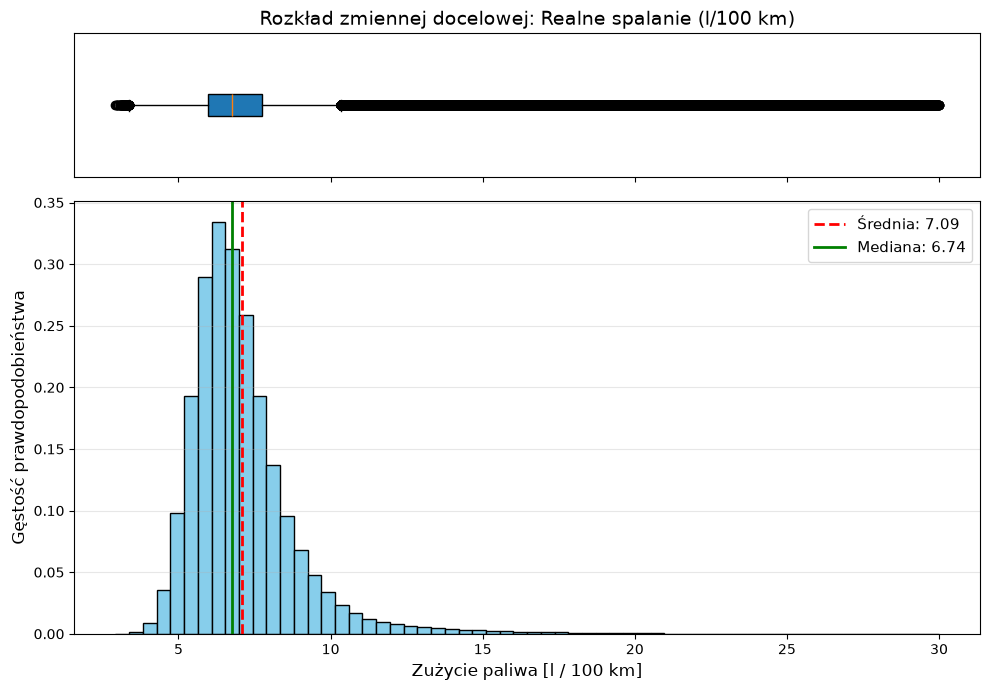

In [29]:
# Wyznaczenie zmiennej docelowej
df_clean['real_fuel_consumption'] = (                      
        df_clean['Total fuel consumed (lifetime) (l)']         
        / df_clean['Total distance travelled (lifetime) (km)'] 
    ) * 100


# Rozkład zmiennej docelowej
fig, (ax_box, ax_hist) = plt.subplots(                                      
    2,                                                                      
    1,                                                                      
    figsize=(10, 7),                                                        
    sharex=True,                                                            
    gridspec_kw={'height_ratios': [0.25, 0.75]},                            
)                                                                           
                                                                            
# 1. Wykres pudełkowy (Boxplot) na górze                                    
ax_box.boxplot(df_clean['real_fuel_consumption'], vert=False, patch_artist=True)  
ax_box.set_title(                                                           
    'Rozkład zmiennej docelowej: Realne spalanie (l/100 km)', fontsize=14   
)                                                                           
ax_box.set_yticks([])                                                       
                                                                            
# 2. Histogram na dole                                                      
n, bins, patches = ax_hist.hist(                                            
    df_clean['real_fuel_consumption'],                                            
    bins=60,                                                                
    color='skyblue',                                                        
    edgecolor='black',                                                      
    density=True,                                                           
)                                                                           
ax_hist.axvline(                                                            
    df_clean['real_fuel_consumption'].mean(),                                     
    color='red',                                                            
    linestyle='--',                                                         
    linewidth=2,                                                            
    label=f"Średnia: {df_clean['real_fuel_consumption'].mean():.2f}",             
)                                                                           
ax_hist.axvline(                                                            
    df_clean['real_fuel_consumption'].median(),                                   
    color='green',                                                          
    linestyle='-',                                                          
    linewidth=2,                                                            
    label=f"Mediana: {df_clean['real_fuel_consumption'].median():.2f}",           
)                                                                           
                                                                            
ax_hist.set_xlabel('Zużycie paliwa [l / 100 km]', fontsize=12)              
ax_hist.set_ylabel('Gęstość prawdopodobieństwa', fontsize=12)               
ax_hist.legend(fontsize=11)                                                 
ax_hist.grid(axis='y', alpha=0.3)                                           
                                                                            
plt.tight_layout()                                                          
plt.show()        